In [1]:
import sys
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
# from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta

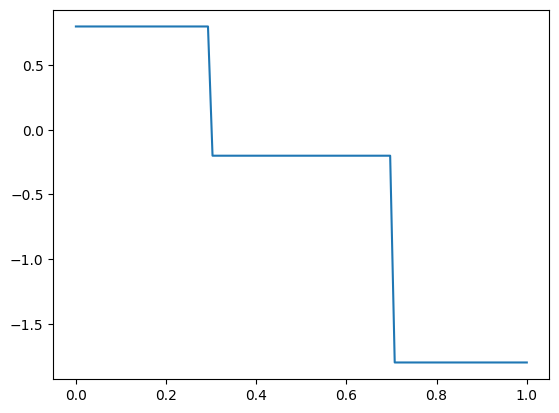

In [2]:
def u0(x):
    """
    Initial condition function u0(t, x) which is independent of t.
    Returns 0.5 for x in [0, 0.3], 0.2 for x in (0.3, 0.6], and -1 for x in (0.6, 1].
    """
    return jnp.where(x <= 0.3, 0.8,
                     jnp.where(x <= 0.7, -0.2, -1.8))

t_min = 0
t_max = 0.5
x_min = 0
x_max = 1

# Boundary at x=x_min
def u1(x):
    return u0(x_min)
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=x_max
def u2(x):
    return u0(x_max)
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

def u_ref(t, x):
    return u0(x-2*t)

def flux(u):
    return 0.5*u**2

x = jnp.linspace(x_min, x_max, 100)
plt.plot(x, u0(x))

In [3]:
N_t = 16
N_x = 32
seq_trainer = SeqMinMaxOptProb(
    input_dim=2, num_segments=5,
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
    N_t=N_t, N_x=N_x, N_bc=2048, N_ic=4096,
    hidden_dims_list=[[32, 32, 32, 32]], seed=0, pre_epochs=0,
    sigma=5, N_perturb=50000, k_h_rf_times=3, f_opt_kh=1,
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="minmax_burgers_strong_double_shock",
    gamma=0, N_test_gamma=1000, adjust_gamma=False, lambda_ic=10, lambda_bc=10, lambda_eqn=1,
    L1reg=0, sampling_method='uniform', notes='',
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    flux=flux, res=res, loss_type='boundary', k=0, f_plot=5000, plt_err_dist=False, plt_mesh=False,
    partition='rect', dg_type='Q1', 
    set_wandb=False,
)

Adding grade 1 with hidden dims [32, 32, 32, 32]
Partition type: rect, dg_type: Q1, p_dof: 4

Training segment [0.0000, 0.1000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 9.476185, lambda_bc: 9.276134, lambda_eqn: 1.133725
Grade 0, Iter 0, loss_eqn: 57.935108, loss_eqn_from_kh: 0.539353 loss_l1: 0.539353, loss_ibc: 4.880929


C:\Users\hao6li\Projects\NN-HCL\Code\my_helpers.py:116: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


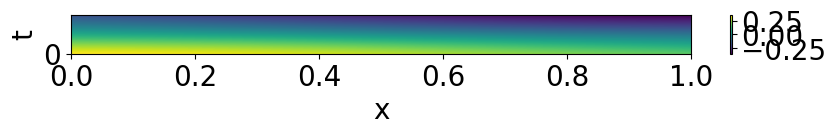

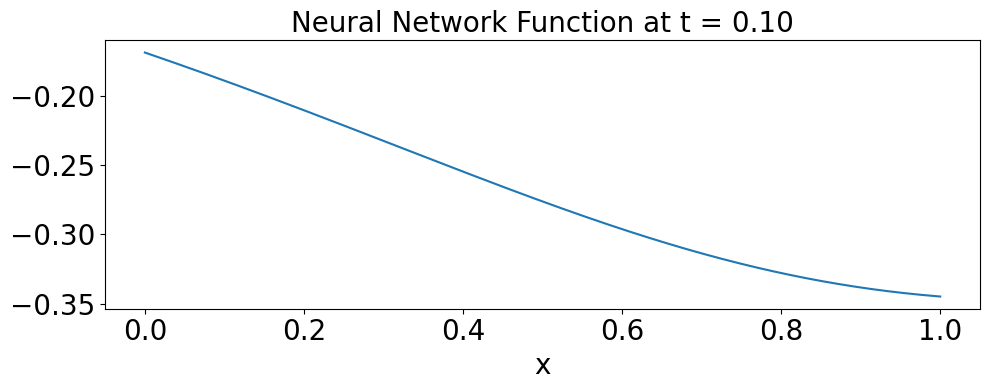

Grade 0, Iter 100, loss_eqn: 27.168486, loss_eqn_from_kh: 0.366941 loss_l1: 0.366942, loss_ibc: 0.178843
Grade 0, Iter 200, loss_eqn: -5.934255, loss_eqn_from_kh: 0.447728 loss_l1: 0.447728, loss_ibc: 0.135624
Grade 0, Iter 300, loss_eqn: 36.838028, loss_eqn_from_kh: 0.430384 loss_l1: 0.430384, loss_ibc: 0.126526
Grade 0, Iter 400, loss_eqn: -12.240512, loss_eqn_from_kh: 0.443171 loss_l1: 0.443171, loss_ibc: 0.118264


KeyboardInterrupt: 

In [4]:
seq_trainer.train_seq()


In [17]:
def u_ref1(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = (x <= 0.5 - 11/10*t)
    cond2 = (0.5 - 11/10*t < x) & (x <= 0.5 - t)
    cond3 = (0.5 - t < x) & (x <= 0.5)
    cond4 = (0.5 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 - t[cond1]/10, -0.2, 0)

    # Case 2
    u[cond2] = np.where(y[cond2] > -9*x[cond2] + 5 - 10*t[cond2], -2, 0)

    # Case 3
    u[cond3] = np.where(y[cond3] > 2*x[cond3]/7 + 5/14 - 5*t[cond3]/7, -2, 0)

    # Case 4
    u[cond4] = np.where(y[cond4] > 1/2 - 3/5*t[cond4] - (5/(28*t[cond4])) * (x[cond4] - 4/5*t[cond4] - 0.5)**2, -2, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - 3*t[cond5]/5, -2, 0.8)
    return u

def u_ref(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = x <= 0.5 - 3*t/5
    cond2 = (0.5 - 3*t/5 < x) & (x <= 0.5 - t/4)
    cond3 = (0.5 - t/4 < x) & (x <= 0.5 + t/2)
    cond4 = (0.5 + t/2 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 + 3*t[cond1]/20, -0.2, 0.5)

    # Case 2
    u[cond2] = np.where(y[cond2] > -8*x[cond2]/7 + 15/14 - 15*t[cond2]/28, -1, 0.5)

    # Case 3
    u[cond3] = np.where(y[cond3] > x[cond3]/6 + 5/12 - 5*t[cond3]/24, -1, 0.5)

    # Case 4
    u[cond4] = np.where(y[cond4] > x[cond4] - (5/(18*t[cond4])) * (x[cond4] + t[cond4] - 0.5)**2, -1, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - t[cond5]/10, -1, 0.8)
    return u



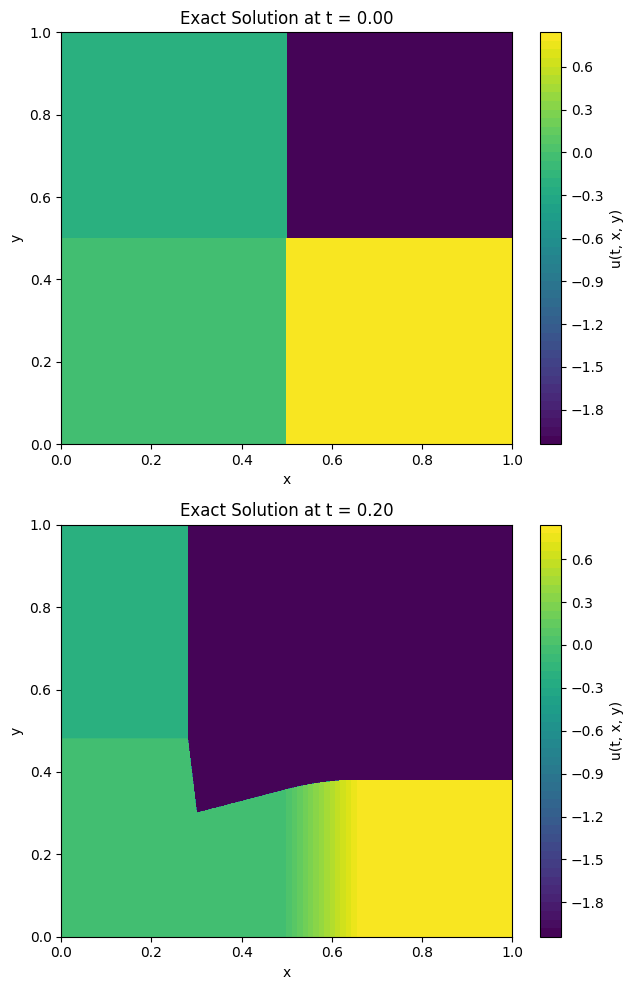

In [19]:
from my_helpers import plot_u_2D, plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together

plot_u_2D([0, 0.2], u_ref2, nx=1000, ny=1000)

In [14]:
x= 0.55
t = 0.1
- (5/(28*t)) * (x - 4/5*t - 0.5)**2

-0.0016071428571428539

In [ ]:
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt

In [20]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_u_2D, plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together
from PwpHex_class import PiecewiseLinearPolynomialsHex
from PwpTetra_class import PiecewiseLinearPolynomialsTetra
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from minmax_opt_class_mgnn import MinMaxOptProb

In [24]:
t_min = 0
t_max = 0.2
x_min = 0
x_max = 1
y_min = 0
y_max = 1

import numpy as np

def flux(u):
    return jnp.array([0.5*u**2, 0.5*u**2])

def u_ref(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = (x <= 0.5 - 11/10*t)
    cond2 = (0.5 - 11/10*t < x) & (x <= 0.5 - t)
    cond3 = (0.5 - t < x) & (x <= 0.5)
    cond4 = (0.5 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 - t[cond1]/10, -0.2, 0)

    # Case 2
    u[cond2] = np.where(y[cond2] > -9*x[cond2] + 5 - 10*t[cond2], -2, 0)

    # Case 3
    u[cond3] = np.where(y[cond3] > 2*x[cond3]/7 + 5/14 - 5*t[cond3]/7, -2, 0)

    # Case 4
    u[cond4] = np.where(y[cond4] > 1/2 - 3/5*t[cond4] - (5/(28*t[cond4])) * (x[cond4] - 4/5*t[cond4] - 0.5)**2, -2, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - 3*t[cond5]/5, -2, 0.8)
    return u

def u0(x, y):
    """
    Initial condition u0(x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min.
    """
    return u_ref(t, x_min*np.zeros_like(t), y)

def u_right(t, y):
    """
    Boundary condition at x = x_max.
    """
    return u_ref(t, x_max*np.ones_like(t), y)

def u_bottom(t, x):
    """
    Boundary condition at y = y_min.
    """
    return u_ref(t, x, y_min*np.zeros_like(t))

def u_top(t, x):
    """
    Boundary condition at y = y_max.
    """
    return u_ref(t, x, y_max*np.ones_like(t))

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

N_t = 10
N_x = 11
N_y = 11
optprob = SeqMinMaxOptProb(
    input_dim=3, num_segments=1, 
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3], flux=flux,
    res=res, loss_type='cai', k=0, f_plot=1000, plt_err_dist=False, plt_mesh=False,
    partition='hex', dg_type='Q1', use_importance_sampling=False, u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: hex, dg_type: Q1, p_dof: 8

Training segment [0.0000, 0.2000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 18.593307, lambda_bc: 18.122259, lambda_eqn: 8.297947
Grade 0, Iter 0, loss_eqn: 0.000140, loss_ibc: 6.418528


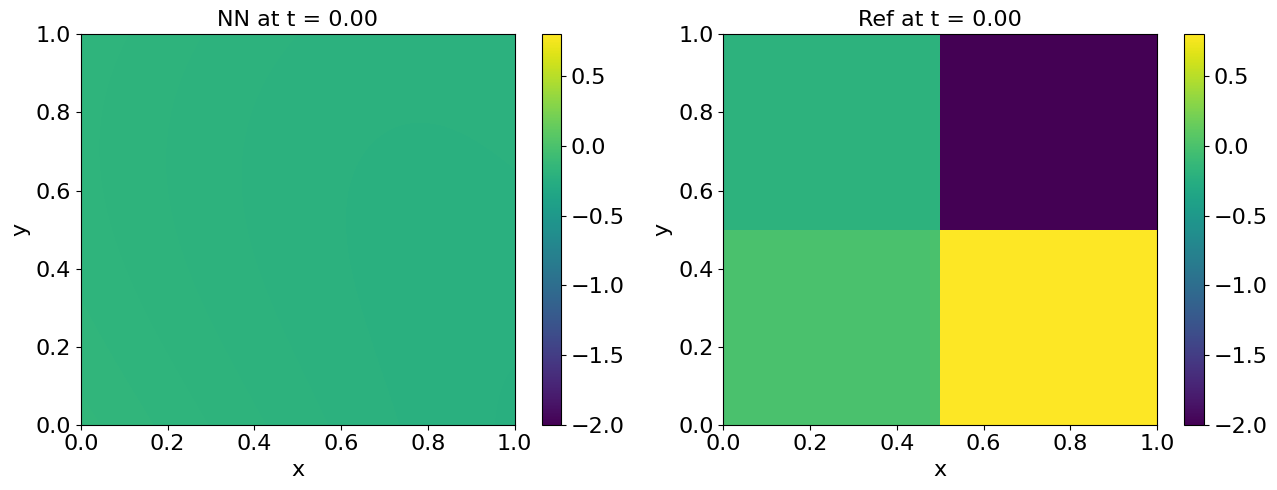

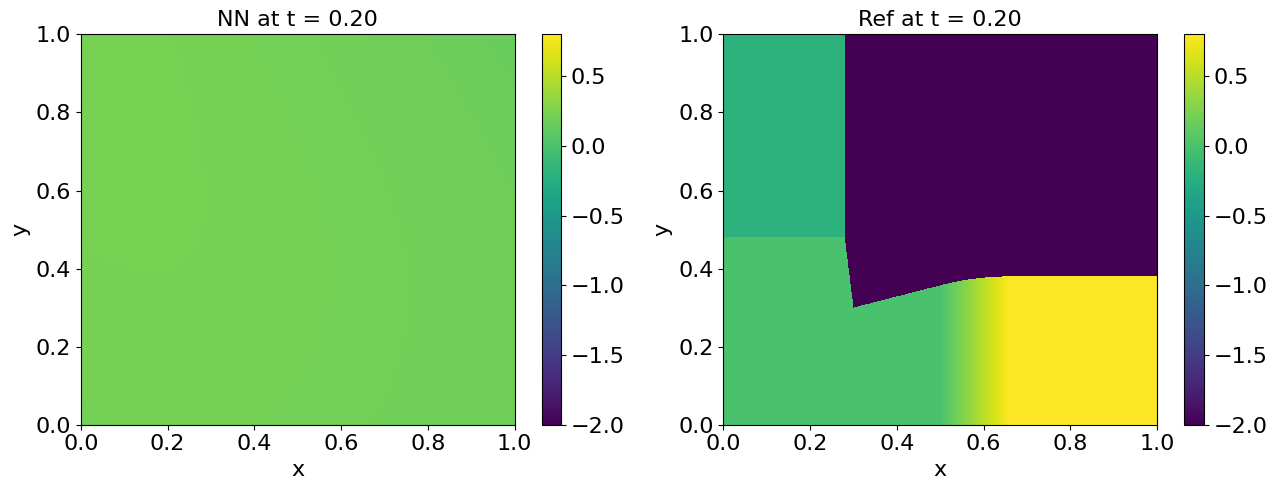

Grade 0, Iter 100, loss_eqn: 0.000152, loss_ibc: 1.392228
Grade 0, Iter 200, loss_eqn: 0.001041, loss_ibc: 0.301621
Grade 0, Iter 300, loss_eqn: 0.000980, loss_ibc: 0.107129
Grade 0, Iter 400, loss_eqn: 0.000814, loss_ibc: 0.053388
Grade 0, Iter 500, loss_eqn: 0.000623, loss_ibc: 0.032667
Grade 0, Iter 600, loss_eqn: 0.000508, loss_ibc: 0.022786
Grade 0, Iter 700, loss_eqn: 0.000457, loss_ibc: 0.016341
Grade 0, Iter 800, loss_eqn: 0.000422, loss_ibc: 0.012624
Grade 0, Iter 900, loss_eqn: 0.000401, loss_ibc: 0.010345
Grade 0, Iter 1000, loss_eqn: 0.000397, loss_ibc: 0.008811


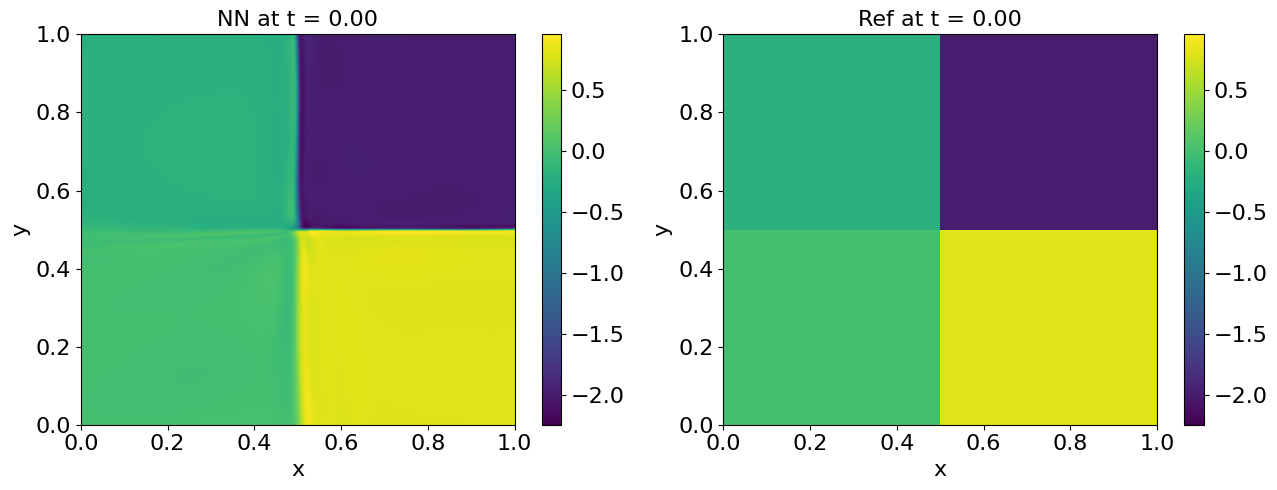

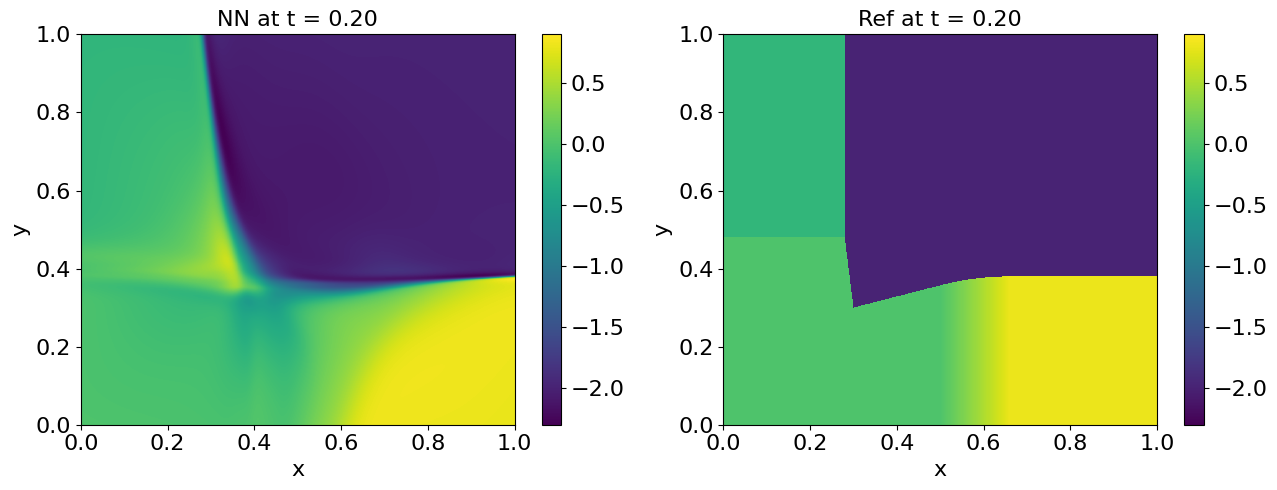

Grade 0, Iter 1100, loss_eqn: 0.000382, loss_ibc: 0.007533
Grade 0, Iter 1200, loss_eqn: 0.000372, loss_ibc: 0.006856
Grade 0, Iter 1300, loss_eqn: 0.000366, loss_ibc: 0.006211
Grade 0, Iter 1400, loss_eqn: 0.000367, loss_ibc: 0.005471
Grade 0, Iter 1500, loss_eqn: 0.000351, loss_ibc: 0.005628
Grade 0, Iter 1600, loss_eqn: 0.000343, loss_ibc: 0.005686
Grade 0, Iter 1700, loss_eqn: 0.000335, loss_ibc: 0.005902
Grade 0, Iter 1800, loss_eqn: 0.000338, loss_ibc: 0.004192
Grade 0, Iter 1900, loss_eqn: 0.000330, loss_ibc: 0.004090
Grade 0, Iter 2000, lambda_ic: 56.908806, lambda_bc: 18.193670, lambda_eqn: 7.574037
Grade 0, Iter 2000, loss_eqn: 0.000321, loss_ibc: 0.004029


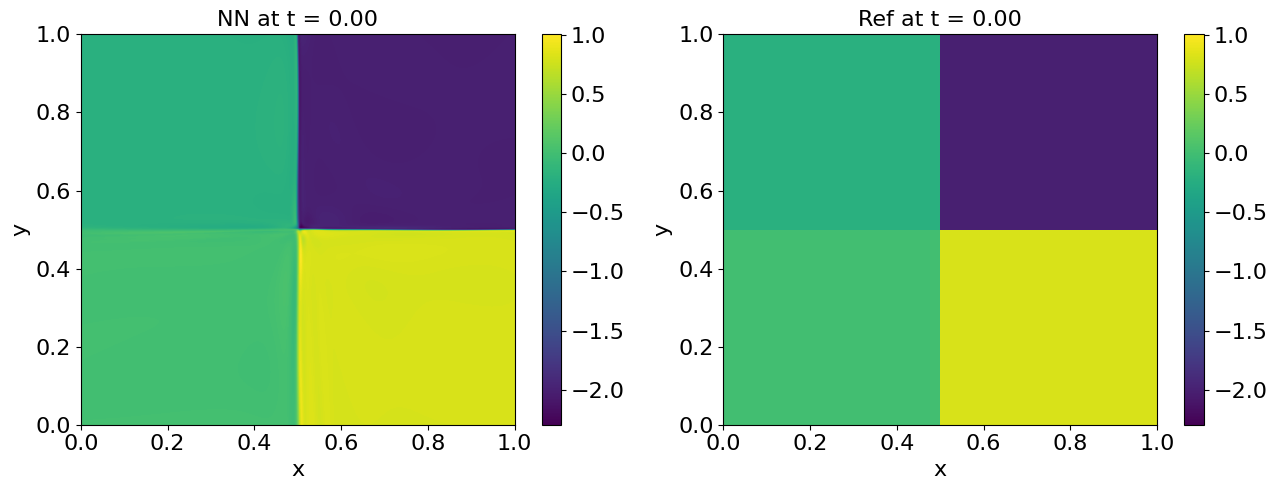

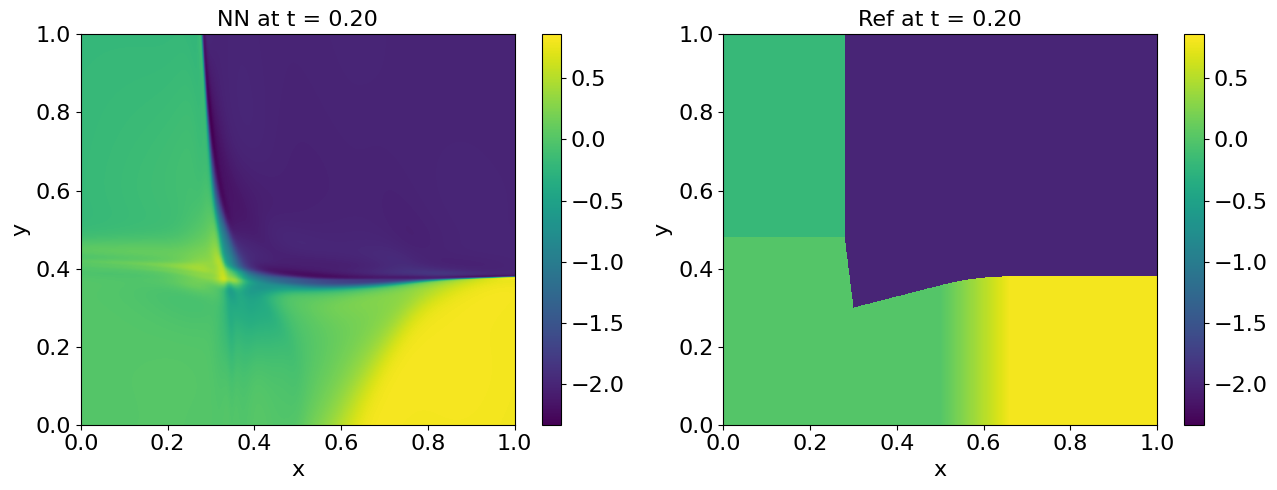

Grade 0, Iter 2100, loss_eqn: 0.000345, loss_ibc: 0.003865
Grade 0, Iter 2200, loss_eqn: 0.000334, loss_ibc: 0.003430
Grade 0, Iter 2300, loss_eqn: 0.000326, loss_ibc: 0.003213
Grade 0, Iter 2400, loss_eqn: 0.000319, loss_ibc: 0.003048
Grade 0, Iter 2500, loss_eqn: 0.000312, loss_ibc: 0.002908
Grade 0, Iter 2600, loss_eqn: 0.000306, loss_ibc: 0.002782
Grade 0, Iter 2700, loss_eqn: 0.000299, loss_ibc: 0.002671
Grade 0, Iter 2800, loss_eqn: 0.000291, loss_ibc: 0.002638
Grade 0, Iter 2900, loss_eqn: 0.000285, loss_ibc: 0.002551
Grade 0, Iter 3000, loss_eqn: 0.000280, loss_ibc: 0.002463


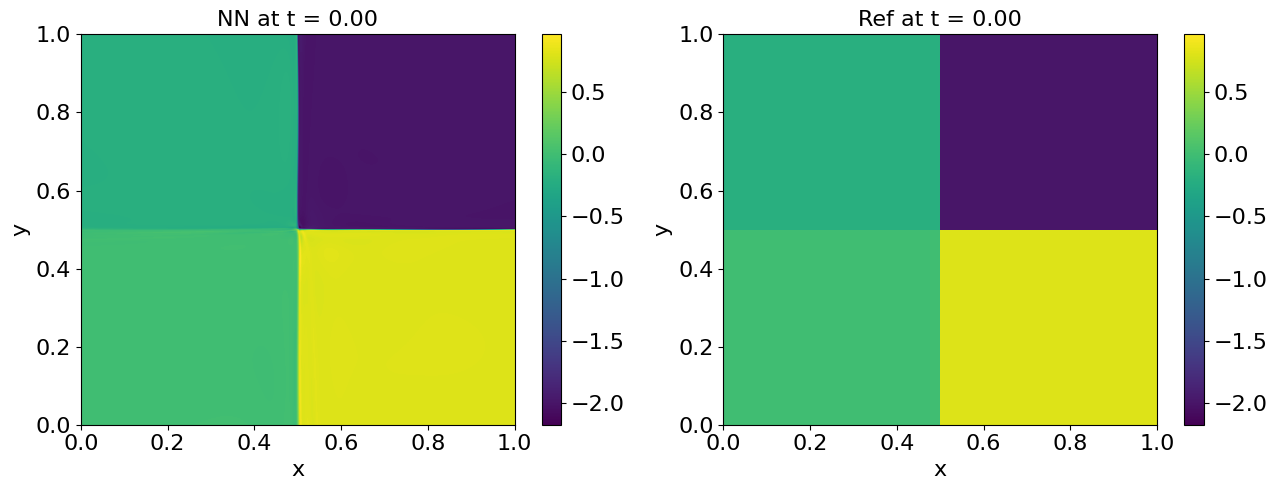

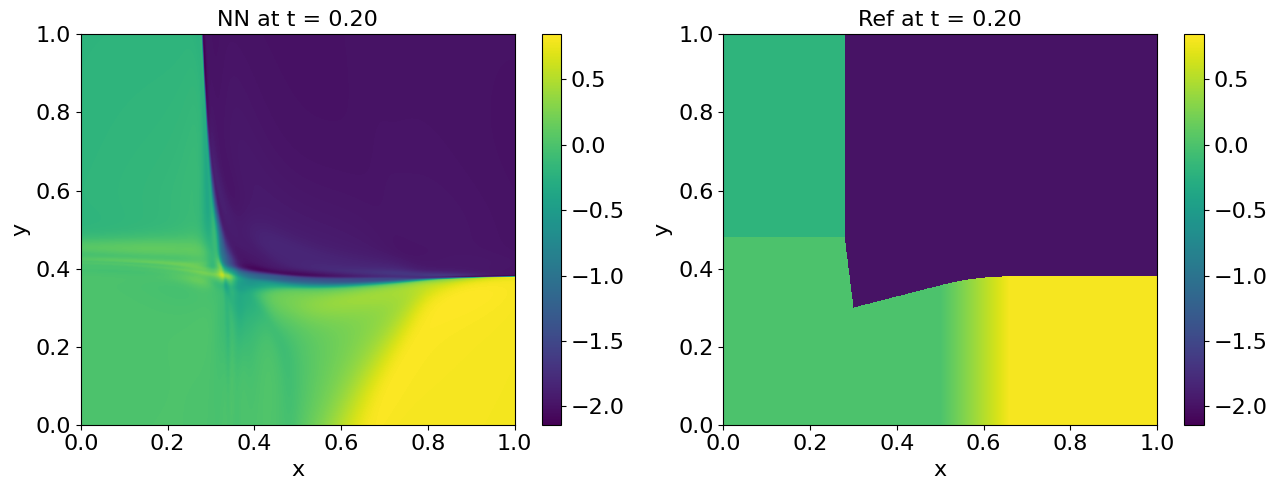

Grade 0, Iter 3100, loss_eqn: 0.000275, loss_ibc: 0.002378
Grade 0, Iter 3200, loss_eqn: 0.000270, loss_ibc: 0.002291
Grade 0, Iter 3300, loss_eqn: 0.000268, loss_ibc: 0.002440
Grade 0, Iter 3400, loss_eqn: 0.000265, loss_ibc: 0.002155
Grade 0, Iter 3500, loss_eqn: 0.000261, loss_ibc: 0.002037
Grade 0, Iter 3600, loss_eqn: 0.000258, loss_ibc: 0.001990
Grade 0, Iter 3700, loss_eqn: 0.000252, loss_ibc: 0.001906
Grade 0, Iter 3800, loss_eqn: 0.000252, loss_ibc: 0.001856
Grade 0, Iter 3900, loss_eqn: 0.000249, loss_ibc: 0.001780
Grade 0, Iter 4000, lambda_ic: 1387.116699, lambda_bc: 18.962387, lambda_eqn: 6.920660
Grade 0, Iter 4000, loss_eqn: 0.000256, loss_ibc: 0.001753


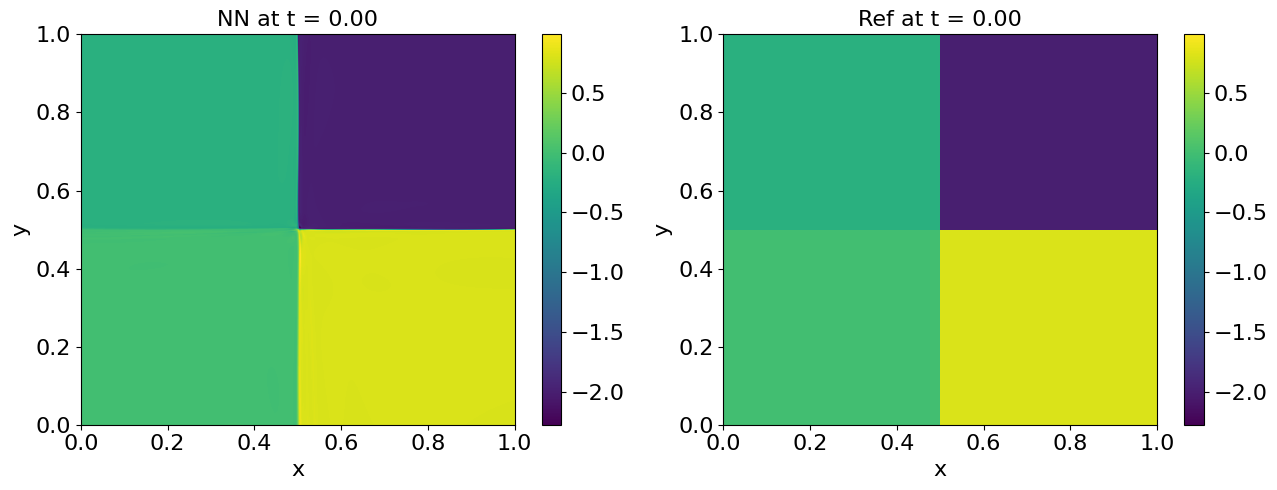

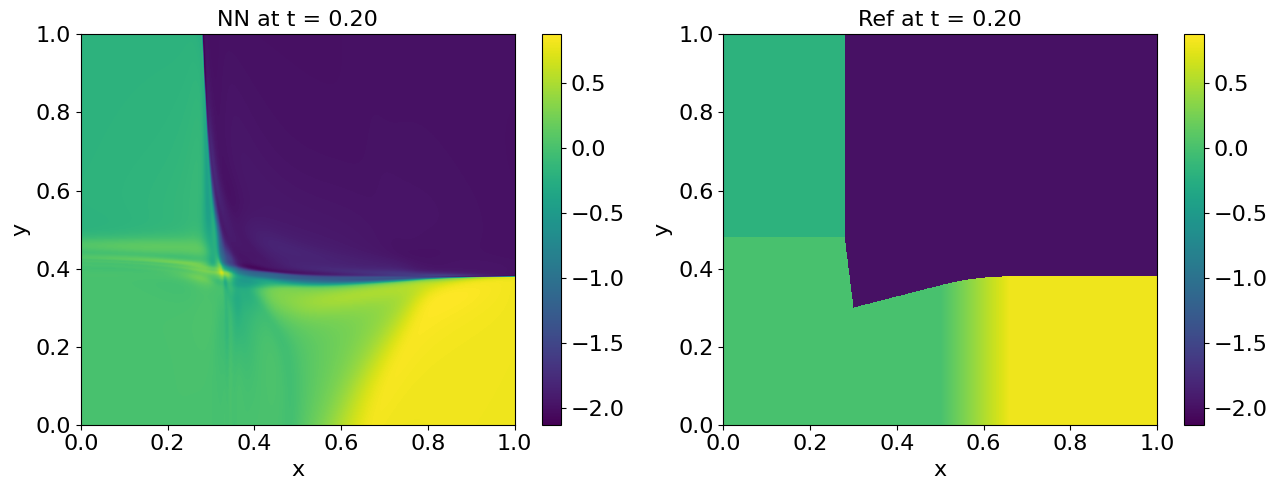

Grade 0, Iter 4100, loss_eqn: 0.000268, loss_ibc: 0.008236
Grade 0, Iter 4200, loss_eqn: 0.000289, loss_ibc: 0.004291
Grade 0, Iter 4300, loss_eqn: 0.000295, loss_ibc: 0.003339
Grade 0, Iter 4400, loss_eqn: 0.000302, loss_ibc: 0.002846
Grade 0, Iter 4500, loss_eqn: 0.000307, loss_ibc: 0.002511
Grade 0, Iter 4600, loss_eqn: 0.000311, loss_ibc: 0.002251
Grade 0, Iter 4700, loss_eqn: 0.000313, loss_ibc: 0.002044
Grade 0, Iter 4800, loss_eqn: 0.000315, loss_ibc: 0.001873
Grade 0, Iter 4900, loss_eqn: 0.000317, loss_ibc: 0.001728
Grade 0, Iter 5000, loss_eqn: 0.000319, loss_ibc: 0.001604


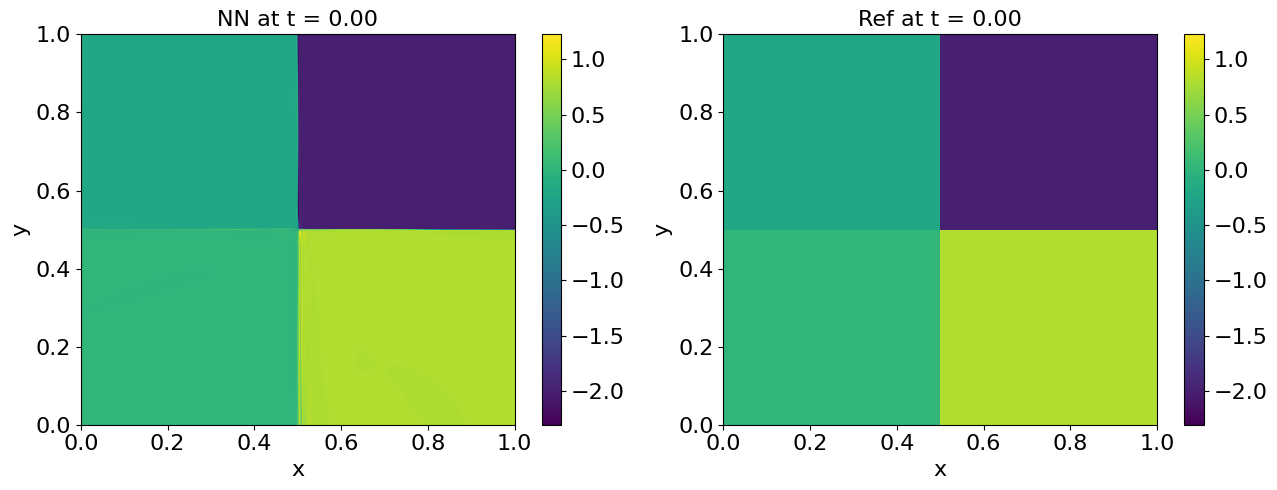

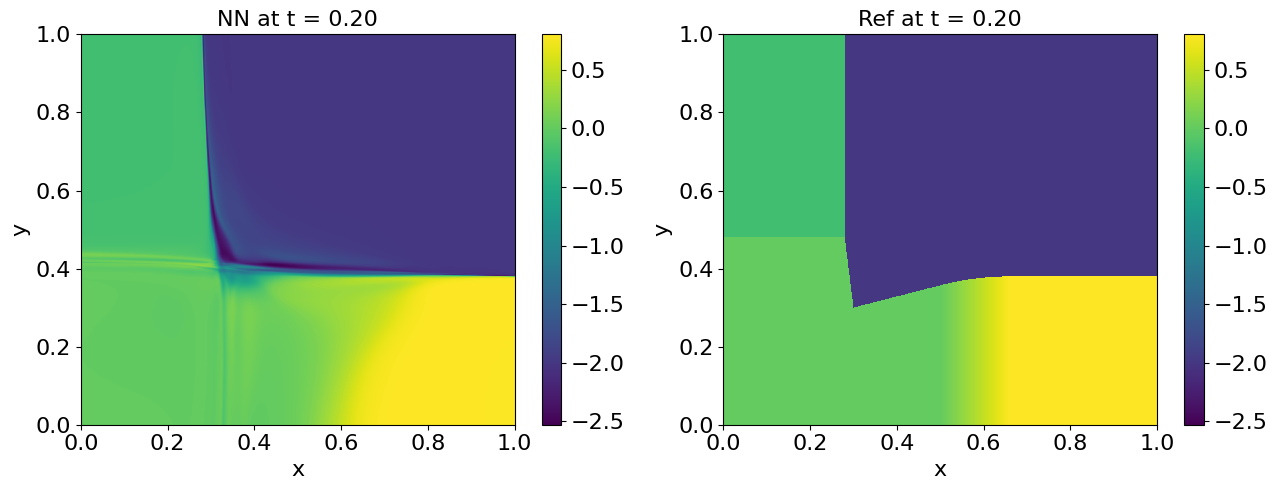

Grade 0, Iter 5100, loss_eqn: 0.000320, loss_ibc: 0.001498
Grade 0, Iter 5200, loss_eqn: 0.000321, loss_ibc: 0.001404
Grade 0, Iter 5300, loss_eqn: 0.000322, loss_ibc: 0.001319
Grade 0, Iter 5400, loss_eqn: 0.000323, loss_ibc: 0.001242
Grade 0, Iter 5500, loss_eqn: 0.000324, loss_ibc: 0.001170
Grade 0, Iter 5600, loss_eqn: 0.000324, loss_ibc: 0.001106
Grade 0, Iter 5700, loss_eqn: 0.000324, loss_ibc: 0.001049
Grade 0, Iter 5800, loss_eqn: 0.000324, loss_ibc: 0.000999
Grade 0, Iter 5900, loss_eqn: 0.000324, loss_ibc: 0.000954
Grade 0, Iter 6000, lambda_ic: 38117.402344, lambda_bc: 436.620117, lambda_eqn: 6.328619
Grade 0, Iter 6000, loss_eqn: 0.000324, loss_ibc: 0.000915


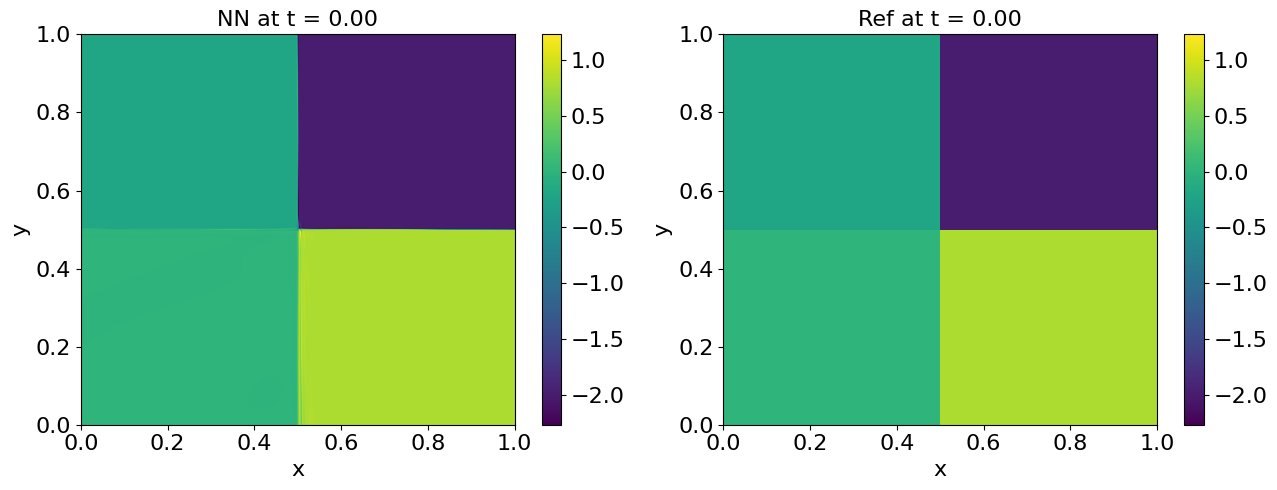

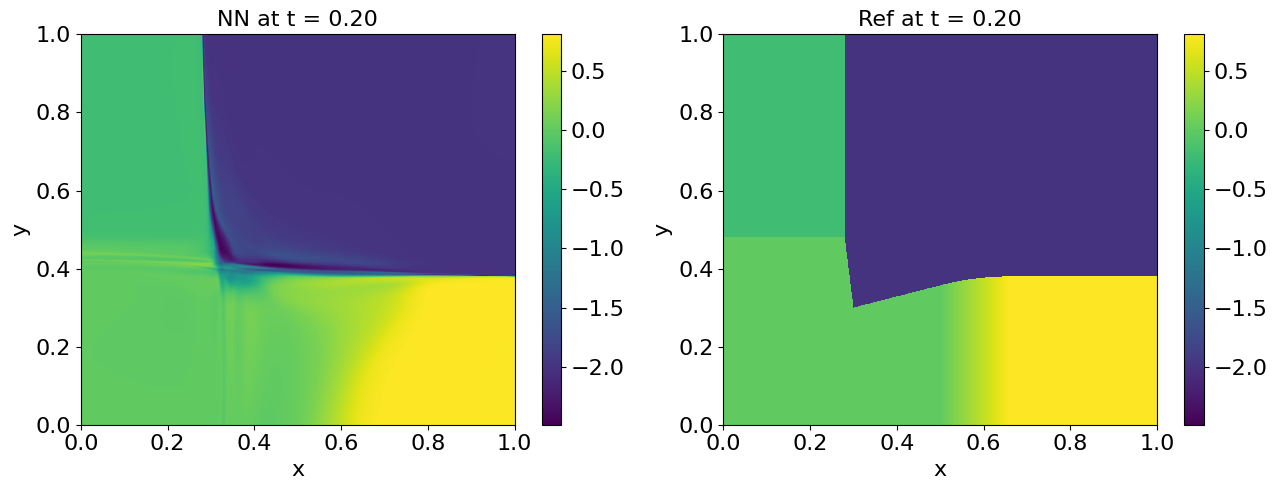

Grade 0, Iter 6100, loss_eqn: 0.000307, loss_ibc: 0.006897


In [ ]:
optprob.train_seq()

In [ ]:
def plot_u_theta_mesh(model, params=None, M_t=1000, M_x=2000, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0, y_min=None, y_max=None, M_y=None, ts=None, upload_fig=False, pwp=None, vals=None):
    """
    Plot the neural network function u_theta over a specified domain [t_min, t_max] x [x_min, x_max].
    Optionally overlay the mesh from PiecewiseLinearPolynomials and denote vals on the meshes.
    The 1D plot at t = t_max is removed, and only the 2D plot is shown.

    Args:
        model: Neural network u_theta.
        params: Parameters (pytree) of the neural network.
        M_t: Number of grid points in the t-direction (default: 1000).
        M_x: Number of grid points in the x-direction (default: 2000).
        t_min: Minimum value for t (default: 0.0).
        t_max: Maximum value for t (default: 0.5).
        x_min: Minimum value for x (default: -1.0).
        x_max: Maximum value for x (default: 1.0).
        y_min: Minimum value for y (for 3D cases, default: None).
        y_max: Maximum value for y (for 3D cases, default: None).
        M_y: Number of grid points in the y-direction (for 3D cases, default: None, falls back to M_x).
        ts: List or array of timestamps for which to plot individual 1D snapshots (default: None).
        upload_fig: Whether to upload the figure to wandb (default: False).
        pwp: Instance of PiecewiseLinearPolynomials(Tri/Rect/Hex/Tetra) to plot the mesh (default: None).
        vals: Values to denote on each mesh (default: None).
    """
    if ts is None:
        ts = []

    input_dim = model.input_dim if hasattr(model, 'input_dim') else 2
    if M_y is None:
        M_y = M_x

    if input_dim == 2:
        # Create a grid for t and x over the specified ranges
        t_grid = np.linspace(t_min, t_max, M_t)
        x_grid = np.linspace(x_min, x_max, M_x)
        t, x = np.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

        # Flatten the grid for batch evaluation
        tx_points = np.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

        # Evaluate u_theta on the grid points
        if params is None:
            u_values = model.forward(tx_points)
        else:
            u_values = model.forward_with_params(params, tx_points) if hasattr(model, 'forward_with_params') else model(params, tx_points)
        u_values = u_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

        # Create larger figure for the 2D plot
        t_range = t_max - t_min
        fig = plt.figure(figsize=(20, 8 + 8 * t_range))
        ax1 = fig.add_subplot(111)

        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1)
        ax1.set_xlabel('x')
        ax1.set_ylabel('t')
        ax1.set_title('Neural Network Function $u_\\theta$')

        # Overlay the mesh and denote vals if pwp and vals are provided
        if pwp is not None:
            if isinstance(pwp, PiecewiseLinearPolynomialsTri):
                triangles = pwp.partitions
                for idx, tri in enumerate(triangles):
                    # Plot the three edges of the triangle
                    ax1.plot([tri[0][1], tri[1][1]], [tri[0][0], tri[1][0]], color='black', alpha=0.5, linewidth=0.5)
                    ax1.plot([tri[1][1], tri[2][1]], [tri[1][0], tri[2][0]], color='black', alpha=0.5, linewidth=0.5)
                    ax1.plot([tri[2][1], tri[0][1]], [tri[2][0], tri[0][0]], color='black', alpha=0.5, linewidth=0.5)
                    center = np.mean(tri, axis=0)
                    if vals is not None:
                        # Denote avg_val at the center
                        ax1.text(center[1], center[0], f'{vals[idx]:.2f}', fontsize=6, color='black', ha='center', va='center')

            elif isinstance(pwp, PiecewiseLinearPolynomialsRect):
                rectangles = pwp.partitions
                for idx, rect in enumerate(rectangles):
                    # Plot the four edges of the rectangle
                    ax1.plot([rect[0][1], rect[1][1]], [rect[0][0], rect[1][0]], color='black', alpha=0.5, linewidth=0.5)  # Bottom
                    ax1.plot([rect[0][1], rect[2][1]], [rect[0][0], rect[2][0]], color='black', alpha=0.5, linewidth=0.5)  # Left
                    ax1.plot([rect[2][1], rect[3][1]], [rect[2][0], rect[3][0]], color='black', alpha=0.5, linewidth=0.5)  # Top
                    ax1.plot([rect[3][1], rect[1][1]], [rect[3][0], rect[1][0]], color='black', alpha=0.5, linewidth=0.5)  # Right
                    center = np.mean(rect, axis=0)
                    if vals is not None:
                        # Denote avg_val at the center
                        ax1.text(center[1], center[0], f'{vals[idx]:.2f}', fontsize=6, color='black', ha='center', va='center')

        # Adjust layout and display the main plot
        plt.tight_layout()
        # Upload the main figure to wandb
        if upload_fig:
            wandb.log({f"u_theta_tmin{t_min:.1f}_tmax_{t_max:.1f}": wandb.Image(fig)})
        plt.show()

    elif input_dim == 3:
        if y_min is None or y_max is None:
            raise ValueError("For input_dim=3, y_min and y_max must be provided.")

        # 2D plot at t = t_max over (x, y)
        x_grid = np.linspace(x_min, x_max, M_x)
        y_grid = np.linspace(y_min, y_max, M_y)
        x, y = np.meshgrid(x_grid, y_grid)  # Shapes: (M_x, M_y)
        
        t = t_max * np.ones_like(x)
        txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)  # Shape: (M_x * M_y, 3)
        
        # Evaluate u_theta on the grid points
        if params is None:
            u_values = model.forward(txy_points)
        else:
            u_values = model.forward_with_params(params, txy_points) if hasattr(model, 'forward_with_params') else model(params, txy_points)
        u_values = u_values.reshape(M_y, M_x)  # Reshape to (M_x, M_y)
        
        # Create figure for the 2D plot at t_max
        fig = plt.figure(figsize=(10, 8))
        ax1 = fig.add_subplot(111)
        
        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, y_grid, u_values, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1)
        ax1.set_xlabel('x')
        ax1.set_ylabel('y')
        ax1.set_title(f'Neural Network Function $u_\\theta$ at t = {t_max:.2f}')
        
        # Overlay the mesh and denote vals for elements sharing a face with t = t_max
        
        if pwp is not None:
            partitions = pwp.partitions
            # Find elements that share a face with t = t_max (i.e., max t == t_max)
            max_t_per_elem = np.max(partitions[:, :, 0], axis=1)
            surface_mask = np.isclose(max_t_per_elem, t_max, atol=1e-6)
            surface_elems = partitions[surface_mask]
            surface_indices = np.where(surface_mask)[0]
            
            if isinstance(pwp, PiecewiseLinearPolynomialsHex):
                
                for i, hex_elem in enumerate(surface_elems):
                    # Find vertices at t = t_max (top face)
                    top_mask = np.isclose(hex_elem[:, 0], t_max, atol=1e-6)
                    top_verts = hex_elem[top_mask]
                    if len(top_verts) == 4:  # Expected for hex top face
                        x_top = top_verts[:, 1]
                        y_top = top_verts[:, 2]
                        # Order for closed rectangle: assuming vertices [lowx lowy, lowx highy, highx lowy, highx highy]
                        # Indices based on binary order: 0: lowx lowy, 1: lowx highy, 2: highx lowy, 3: highx highy
                        indices = np.array([0, 1, 3, 2])
                        ax1.plot(np.append(x_top[indices], x_top[indices[0]]), np.append(y_top[indices], y_top[indices[0]]), 
                                 color='black', alpha=0.5, linewidth=0.5)
                        
                        center_x = np.mean(x_top)
                        center_y = np.mean(y_top)
                        if vals is not None:
                            ax1.text(center_x, center_y, f'{vals[surface_indices[i]]:.2f}', fontsize=6, color='black', ha='center', va='center')
            
            elif isinstance(pwp, PiecewiseLinearPolynomialsTetra):
                for i, tet in enumerate(surface_elems):
                    # Find vertices at t = t_max
                    top_mask = np.isclose(tet[:, 0], t_max, atol=1e-6)
                    top_verts = tet[top_mask]
                    if len(top_verts) == 3:  # Triangle face
                        x_top = top_verts[:, 1]
                        y_top = top_verts[:, 2]
                        ax1.plot(np.append(x_top, x_top[0]), np.append(y_top, y_top[0]), 
                                 color='black', alpha=0.5, linewidth=0.5)
                        
                        center_x = np.mean(x_top)
                        center_y = np.mean(y_top)
                        if vals is not None:
                            ax1.text(center_x, center_y, f'{vals[surface_indices[i]]:.2f}', fontsize=6, color='black', ha='center', va='center')
            else:
                print("No such class!!!")
        plt.tight_layout()
        # Upload the figure to wandb
        if upload_fig:
            wandb.log({f"u_theta_at_tmax_{t_max:.1f}": wandb.Image(fig)})
        plt.show()

    # Plot separate figures for each timestamp in ts (adapted for dimension)
    for t_val in ts:
        if input_dim == 2:
            # Find the closest index in t_grid
            idx = np.argmin(np.abs(t_grid - t_val))
            # Create a new figure for the snapshot
            fig, ax = plt.subplots(1, 1, figsize=(10, 4))
            ax.plot(x_grid, u_values[idx, :])
            ax.set_xlabel('x')
            ax.set_ylabel('$u_\\theta(t, x)$')
            ax.set_title(f'Neural Network Function at t = {t_val:.2f} (closest t = {t_grid[idx]:.2f})')
            plt.tight_layout()
            plt.show()
        elif input_dim == 3:
            # Similar to t_max plot but without mesh/vals (or adapt if needed)
            x, y = np.meshgrid(x_grid, y_grid)
            t = t_val * np.ones_like(x)
            txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)
            u_values_ts = model.forward(txy_points).reshape(M_y, M_x)
            fig_ts, ax_ts = plt.subplots(1, 1, figsize=(10, 8))
            pcm_ts = ax_ts.pcolormesh(x_grid, y_grid, u_values_ts, shading='nearest', cmap='viridis')
            fig_ts.colorbar(pcm_ts, ax=ax_ts)
            ax_ts.set_xlabel('x')
            ax_ts.set_ylabel('y')
            ax_ts.set_title(f'Neural Network Function $u_\\theta$ at t = {t_val:.2f}')
            plt.tight_layout()
            plt.show()

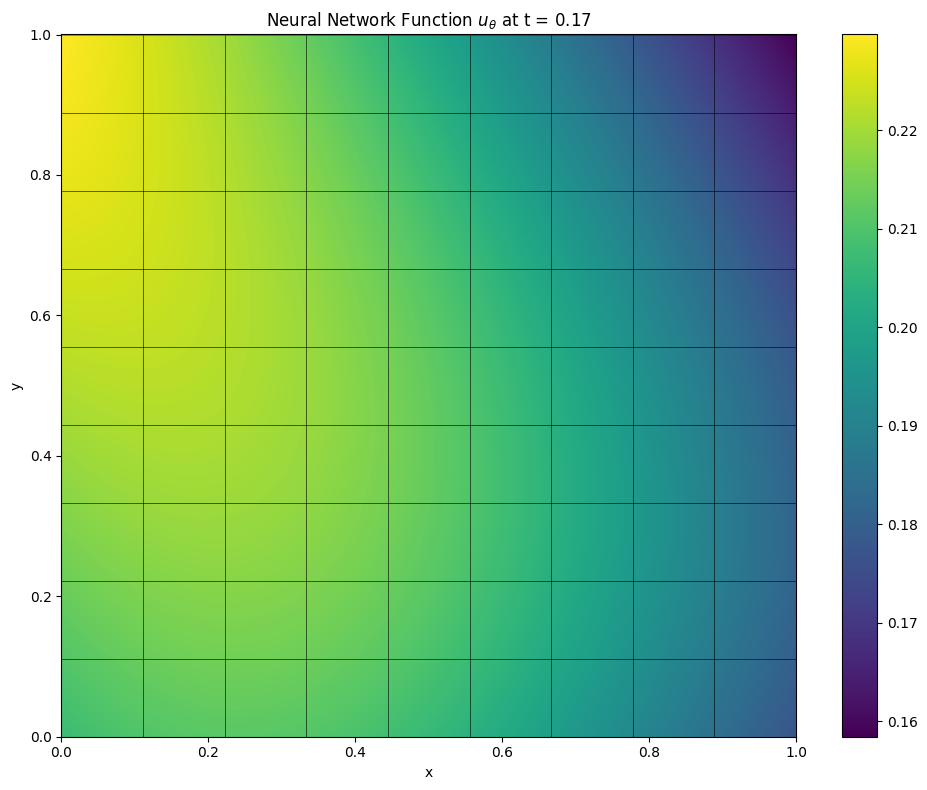

In [7]:
self = optprob.segments[0]
plot_u_theta_mesh(self.model, t_min=self.t_min, t_max=self.t_max, x_min=self.x_min,
                            x_max=self.x_max, y_min=0, y_max=1, pwp=self.pwp)

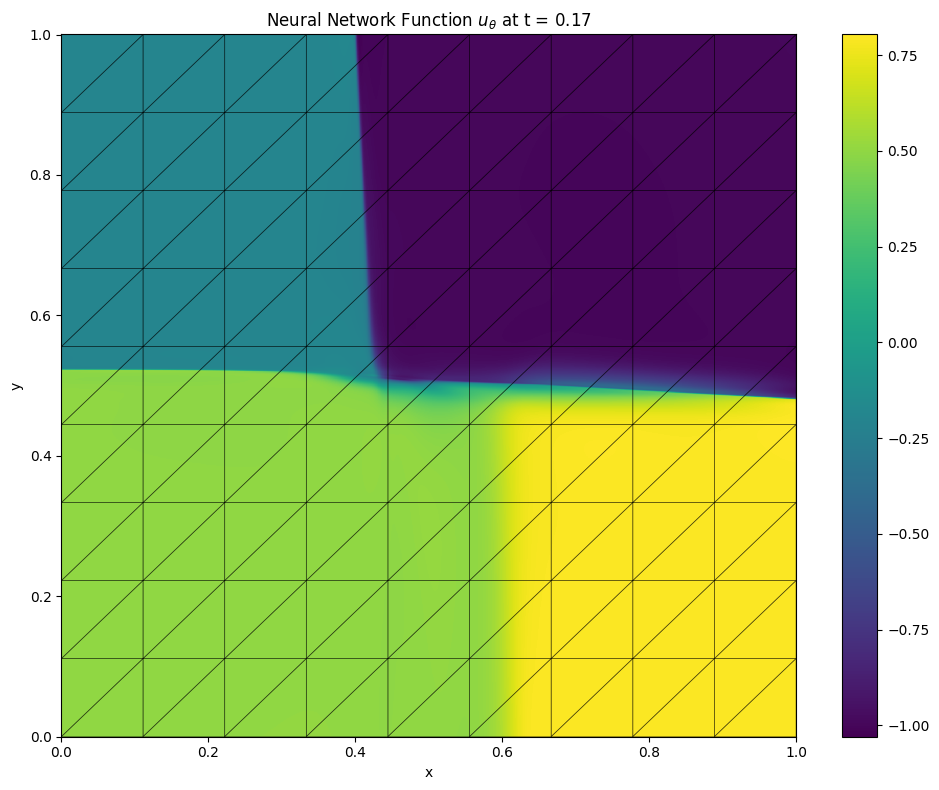

In [37]:
self = optprob.segments[0]
plot_u_theta_mesh(self.model, t_min=self.t_min, t_max=self.t_max, x_min=self.x_min,
                            x_max=self.x_max, y_min=0, y_max=1, pwp=self.pwp)

In [12]:
import numpy as np

def u_ref(t, x, y):
    """
    Reference solution u(t, x, y).
    Returns 0 if y > 0.5 + 0.5*t, else 1.
    """
    return np.where(y > 0.5 + 0.5 * t, 0, 1)

def u0(x, y):
    """
    Initial condition u0(x, y) = u(0, x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder, since independent of x

def u_right(t, y):
    """
    Boundary condition at x = x_max (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder

def u_bottom(t, x):
    """
    Boundary condition at y = y_min (independent of x, so same as u_ref with y=y_min).
    """
    return u_ref(t, x, np.zeros_like(x))  # y=0 as placeholder, but function needs y

def u_top(t, x):
    """
    Boundary condition at y = y_max (independent of x, so same as u_ref with y=y_max).
    """
    return u_ref(t, x, np.ones_like(x))  # y=0 as placeholder, adjust if y_max known

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

In [13]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1
N_t = 8
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(input_dim=3, total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[2e-4, 1e-3, 1e-3], grade_epochs=[101, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 9.413791
Grade 0, Iter 0, lambda_ic: 18.335306, lambda_bc: 18.339373, lambda_eqn: 1.145638
Grade 0, Iter 0, loss_eqn: 0.410825, loss_eqn_from_kh: 0.410592, loss_l1: 0.410592, loss_ibc: 3.018623


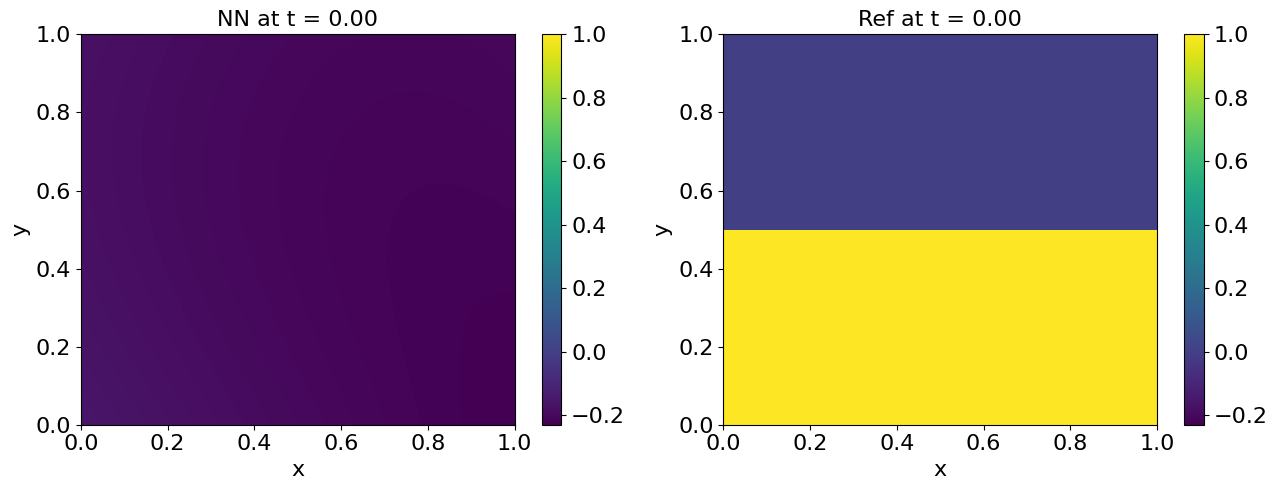

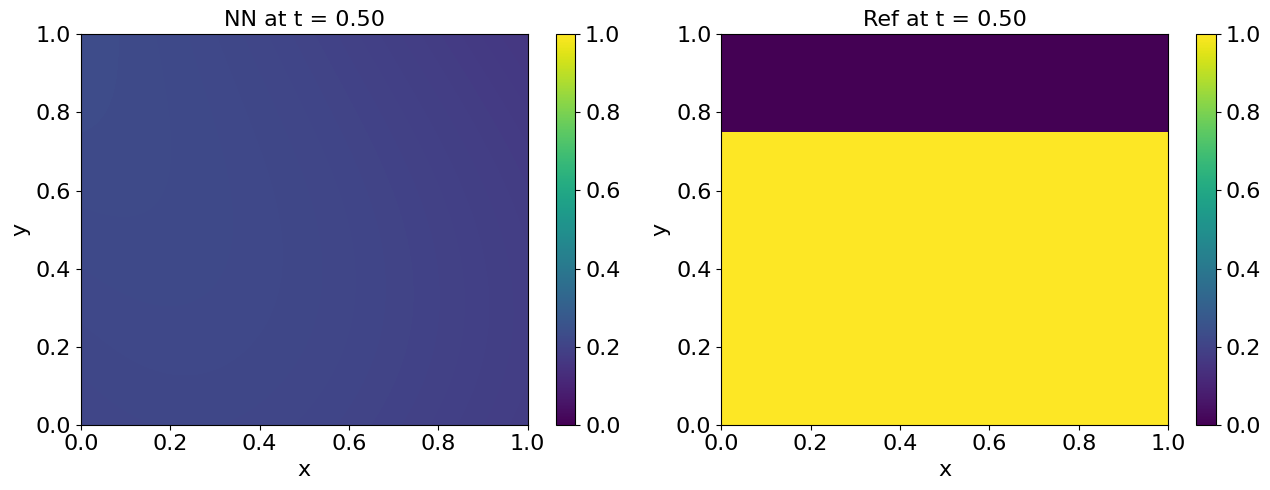

Grade 0, Iter 100, loss_eqn: 0.234396, loss_eqn_from_kh: 0.234049, loss_l1: 0.234049, loss_ibc: 0.275619
Train time for stage1: 92.617730 seconds

Plotting after training segment [0.0000, 0.5000]


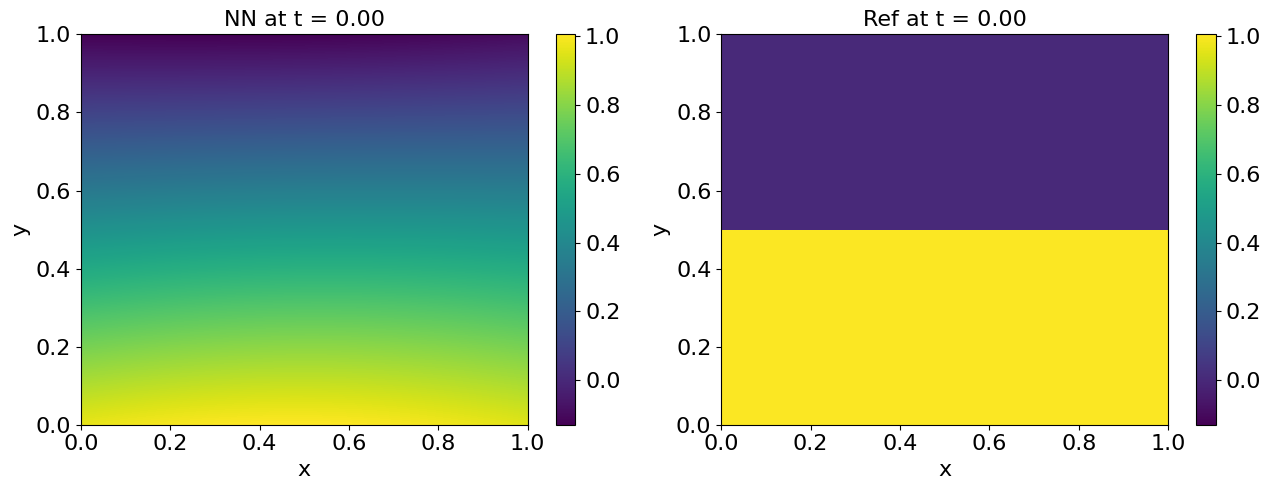

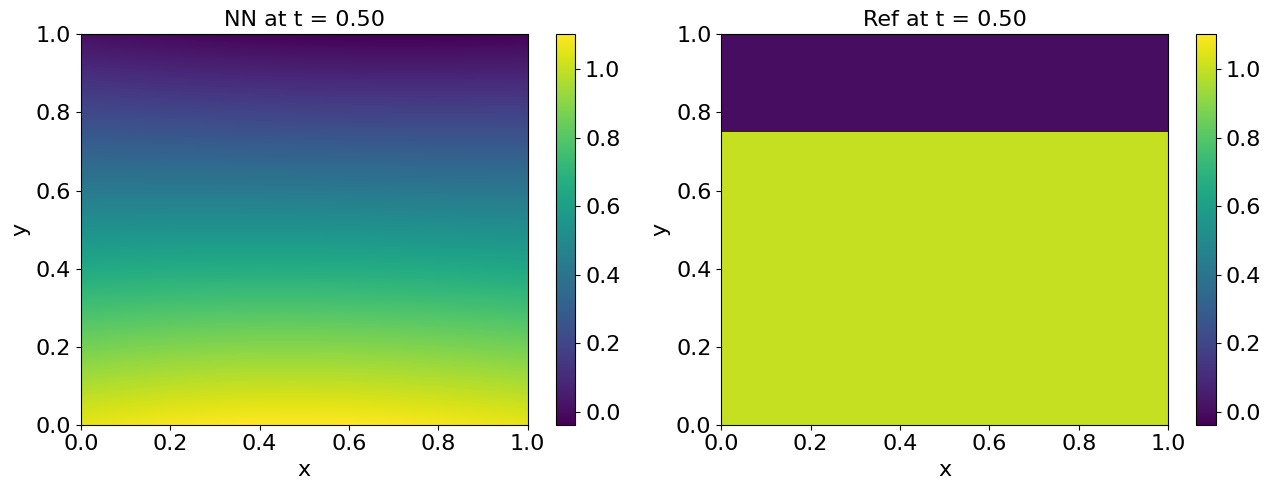

In [14]:
optprob.train_seq()

In [7]:
self = optprob.segments[0]
self.input_dim
self.u_ref(0.5, 1, 0.5)

IndexError: list index out of range

In [ ]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [8]:
self = optprob
params = optprob.model.mlps[0].params
self.gen_funcs(0)
self.pwp.coeffs, self.key, loss_eqn_from_kh, loss_l1, loss_each_elem = self.maximize_kh_step(params, self.key)

In [9]:
Nt = self.pwp.N_elements
quad_points = self.pwp.quad_points_parti
u_values_all = self.u_eval(params, quad_points)
quad_weights = self.pwp.quad_weights_parti
avg_vals = jnp.einsum('ij,ij->i', u_values_all, quad_weights)/self.elem_meas
init_coeffs_all = jnp.hstack([avg_vals[..., None] , jnp.zeros((Nt, self.p_dof - 1))])
perturbations_all = self.sigma * jax.random.uniform(self.key, (self.N_perturb, self.p_dof), minval=-1, maxval=1)
perturbed_coeffs_all = init_coeffs_all[:, None, :] + perturbations_all[None, :, :]

In [35]:
parti_idx = 0
quad_points = self.pwp.quad_points_parti[parti_idx]
quad_weights = self.pwp.quad_weights_parti[parti_idx]
u_quad = self.u_eval(params, quad_points)
grad_u_tx = self.grad_u(params, quad_points)

In [36]:
quad_points.shape

(64, 3)

In [11]:
u_t, u_x, u_y = grad_u_tx[:, 0], grad_u_tx[:, 1], grad_u_tx[:, 2]
residual = self.res(u_quad, u_t, u_x, u_y).flatten()
p_coeffs_all = perturbed_coeffs_all[parti_idx]
k_h_quad_all = (p_coeffs_all[:, 0][:, None] + 
                p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
                p_coeffs_all[:, 2][:, None] * quad_points[:, 1] + 
                p_coeffs_all[:, 3][:, None] * quad_points[:, 2]
               )
k_h_quad_all1 = jnp.einsum('ik,kj->ij', p_coeffs_all[:, 1:], quad_points.T) + p_coeffs_all[:, 0][:, None]

In [12]:
jnp.min(k_h_quad_all1-k_h_quad_all)

Array(-9.536743e-07, dtype=float32)

In [33]:
quad_points = self.pwp.quad_points
p_coeffs_quad = self.pwp.coeffs[self.pwp.element_indices]
k_h_quad = p_coeffs_quad[:, 0] + jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1)
k_h_quad1 = jnp.einsum('ij, ij->i', p_coeffs_quad[:, 1:], quad_points) + p_coeffs_quad[:, 0]

In [34]:
jnp.max(jnp.abs(k_h_quad-k_h_quad1))

Array(0., dtype=float32)

In [ ]:
jnp.max(k_h_quad-k_h_quad1)

In [28]:
jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1).shape

(41472,)

In [37]:
self.pwp.quad_points.shape

(41472, 3)

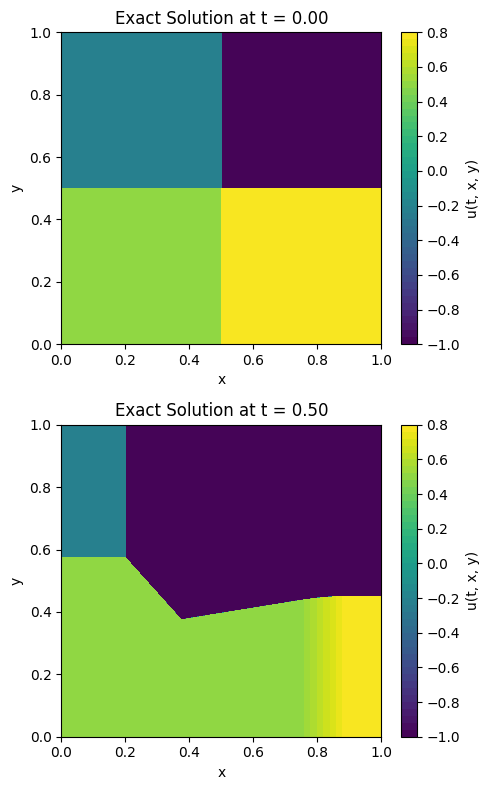

In [12]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [77]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0

tau = (t_max - t_min) / N_t
hx = (x_max - x_min) / N_x
hy = (y_max - y_min) / N_y
t_starts = jnp.linspace(t_min, t_max - tau, N_t)
x_starts = jnp.linspace(x_min, x_max - hx, N_x)
y_starts = jnp.linspace(y_min, y_max - hy, N_y)
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
# Define the 8 vertices for each hexahedron using binary offsets
offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
deltas = jnp.array([tau, hx, hy])
offsets = offsets_bin * deltas  # (8,3)
lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)

In [83]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts)
xl.shape

(5, 10, 2)

In [69]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)

# Tensor product for 3D
t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)

In [79]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
tl.shape

(10, 5, 2)

In [72]:
t_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [73]:
x_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967]],

       [[ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ]],

       [[ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

Text(0.5, 1.0, 'Neural Network Function $u_\\theta$ at t = 1.00')

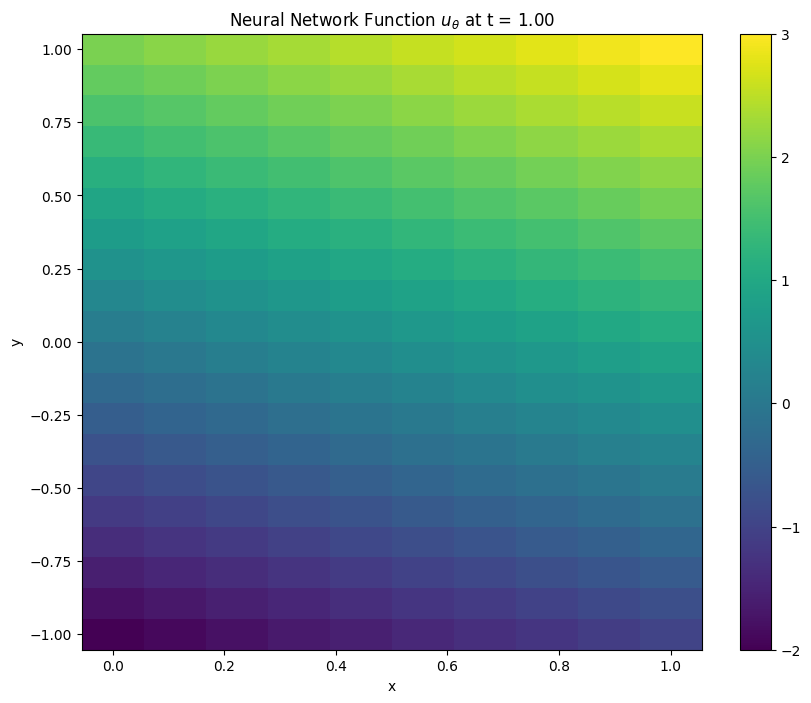

In [70]:
x_min = 0
x_max = 1
M_x = 10
y_min = -1
y_max = 1
M_y = 20
t_max = 1
# 2D plot at t = t_max over (x, y)
x_grid = np.linspace(x_min, x_max, M_x)
y_grid = np.linspace(y_min, y_max, M_y)
x, y = np.meshgrid(x_grid, y_grid, indexing='ij')  # Shapes: (M_x, M_y)
        
t = t_max * np.ones_like(x)
txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)  # Shape: (M_x * M_y, 3)
        
# Evaluate u_theta on the grid points
u_values = txy_points[:,1]+2*txy_points[:,2]
u_values = u_values.reshape(x.shape)  # Reshape to (M_y, M_x)
        
# Create figure for the 2D plot at t_max
fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_subplot(111)
        
# 2D color mesh plot
pcm = ax1.pcolormesh(x_grid, y_grid, u_values.T, shading='nearest', cmap='viridis')
fig.colorbar(pcm, ax=ax1)
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title(f'Neural Network Function $u_\\theta$ at t = {t_max:.2f}')

In [56]:
x_grid.shape

(10,)

In [54]:
x, y = np.meshgrid(x_grid, y_grid)

In [55]:
x.shape

(20, 10)

In [58]:
x, y = np.meshgrid(x_grid, y_grid, indexing='ij')

In [16]:
class PiecewiseLinearPolynomialsRect1:
    def __init__(self, N_t, N_x, t_min=0.0, t_max=1.0, x_min=-1.0, x_max=1.0, gauss_order=3, bdry_order=3, dg_type='Q1'):
        """
        Initialize a rectangular mesh with custom ranges.

        Args:
            N_t: Number of divisions along the t-axis.
            N_x: Number of divisions along the x-axis.
            t_min: Minimum value for t (default: 0.0).
            t_max: Maximum value for t (default: 1.0).
            x_min: Minimum value for x (default: -1.0).
            x_max: Maximum value for x (default: 1.0).
            gauss_order: Order of Gauss quadrature (number of points per direction, default: 2).
            bdry_order: Order of boundary quadrature (number of points per edge, default: 3).
        """
        self.N_t = N_t
        self.N_x = N_x
        self.t_min = t_min
        self.t_max = t_max
        self.x_min = x_min
        self.x_max = x_max
        self.gauss_order = gauss_order
        self.bdry_order = bdry_order
        self.N_elements = N_t * N_x  # Number of rectangles
        self.partitions = self._generate_rectangles()
        if dg_type == 'Q1':
            self.p_dof = 4
        elif dg_type == 'P1':
            self.p_dof = 3
        self.coeffs = jnp.zeros((self.N_elements, self.p_dof))  # Coefficients a, b, c for a + b*t + c*x per rectangle
        self.quad_points, self.quad_weights, self.quad_element_indices, self.quad_points_parti, self.quad_weights_parti = self._setup_quadrature()
        # self.bdry_points_parti, self.bdry_weights_parti = self.get_boundary_quadrature()
        # self.normals = self.compute_normals()

    def _generate_rectangles(self):
        """Generate the rectangles for the mesh with custom ranges."""
        self.ht = (self.t_max - self.t_min) / self.N_t  # Step size along t
        self.hx = (self.x_max - self.x_min) / self.N_x   # Step size along x

        t_starts = jnp.linspace(self.t_min, self.t_max - self.ht, self.N_t)
        x_starts = jnp.linspace(self.x_min, self.x_max - self.hx, self.N_x)
        tl, xl = jnp.meshgrid(t_starts, x_starts)
        # Define the 4 vertices for each hexahedron using binary offsets
        offsets_bin = jnp.array([[int(b) for b in f'{i:02b}'] for i in range(4)], dtype=jnp.float32)  # (4, 2) binary 00 to 11
        deltas = jnp.array([self.ht, self.hx])
        offsets = offsets_bin * deltas  # (4,2)
        lowers = jnp.stack([tl.ravel(), xl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 2)
        partitions = lowers + offsets[None, :, :]  # (N_elements, 4, 2)
        return partitions

    def _setup_quadrature(self):
        """
        Setup Gauss quadrature points and weights for rectangular mesh.

        Returns:
            quad_points: Quadrature points, shape (N_quad, 2).
            quad_weights: Quadrature weights, shape (N_quad,).
            quad_element_indices: Indices of rectangles, shape (N_quad,).
            quad_points_parti: Quadrature points per rectangle, shape (N_elements, self.Nq, 2).
            quad_weights_parti: Quadrature weights per rectangle, shape (N_elements, self.Nq).
        """
        self.Nq = self.gauss_order ** 2  # Number of quadrature points per rectangle

        # Gauss-Legendre nodes and weights in [-1, 1]
        nodes, weights = np.polynomial.legendre.leggauss(self.gauss_order)
        nodes_jnp = jnp.array(nodes)
        weights_jnp = jnp.array(weights)

        # Tensor product for 2D
        t_nodes, x_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp)
        t_weights, x_weights = jnp.meshgrid(weights_jnp, weights_jnp)
        quad_weights_2d = (t_weights * x_weights).ravel()

        # Function to map [-1,1]x[-1,1] to rectangle [t_low, t_high]x[x_low, x_high]
        def map_to_rect(rect):
            t_low, x_low = rect[0]
            t_high, x_high = rect[3]
            t_scale = (t_high - t_low) / 2
            x_scale = (x_high - x_low) / 2
            t_center = (t_high + t_low) / 2
            x_center = (x_high + x_low) / 2
            t_points = t_center + t_nodes.ravel() * t_scale
            x_points = x_center + x_nodes.ravel() * x_scale
            points = jnp.stack([t_points, x_points], axis=1)
            weights = quad_weights_2d * (t_scale * x_scale)
            return points, weights

        # Vectorize over rectangles
        quad_points_rect, quad_weights_rect = vmap(map_to_rect)(self.partitions)

        # Flatten for global quadrature
        quad_points = quad_points_rect.reshape(-1, 2)
        quad_weights = quad_weights_rect.reshape(-1)
        quad_element_indices = jnp.repeat(jnp.arange(self.N_elements), self.Nq)

        return quad_points, quad_weights, quad_element_indices, quad_points_rect, quad_weights_rect

In [87]:
import numpy as np
from scipy import integrate
from PwpTri_class import PiecewiseLinearPolynomialsTri

# Test parameters
t_min = -1.0/20
t_max = 1.9/20
x_min = -1.0/20
x_max = 1.0/20
N_t = 1
N_x = 1
rf_times = 2  # Refinement level, adjust as needed (0,1,2)

# Instantiate the class
mesh = PiecewiseLinearPolynomialsRect(N_t, N_x, t_min=t_min, t_max=t_max, x_min=x_min, x_max=x_max, rf_times=rf_times)
mesh1 = PiecewiseLinearPolynomialsRect1(N_t, N_x, t_min=t_min, t_max=t_max, x_min=x_min, x_max=x_max, gauss_order=rf_times)
mesh2 = PiecewiseLinearPolynomialsTri(N_t, N_x, t_min=t_min, t_max=t_max, x_min=x_min, x_max=x_max, rf_times=rf_times)

# Define a test function
def f(t, x):
    return np.sign(t) * (1+np.cos(1.2*x))  # Integrable function

# Compute integral using the class's quadrature
quad_points = mesh.quad_points
quad_weights = mesh.quad_weights
quad_points1 = mesh1.quad_points
quad_weights1 = mesh1.quad_weights
quad_points2 = mesh2.quad_points
quad_weights2 = mesh2.quad_weights
integral_quad = np.sum(f(quad_points[:, 0], quad_points[:, 1]) * quad_weights)
integral_quad1 = np.sum(f(quad_points1[:, 0], quad_points1[:, 1]) * quad_weights1)
integral_quad2 = np.sum(f(quad_points2[:, 0], quad_points2[:, 1]) * quad_weights2)

# Compute reference integral using scipy.integrate.dblquad
def integrand(x, t):  # Note: dblquad integrates dy dx, but here y=x, x=t? Wait, dblquad(func, a, b, gfun, hfun) where func(y, x)
    return f(t, x)  # Wait, dblquad integrates ∫_x=a^b ∫_y=g(x)^h(x) func(y,x) dy dx
# So to integrate ∫_t=tmin^tmax ∫_x=xmin^xmax f(t,x) dx dt, set as ∫_t=tmin^tmax ∫_x=xmin^xmax f(t,x) dx dt, so func(x, t) = f(t, x), but dblquad does inner dy (x) outer dx (t)
integral_ref, abserr = integrate.dblquad(lambda x, t: f(t, x), t_min, t_max, lambda t: x_min, lambda t: x_max)

print(f"Quadrature integral: {integral_quad}")
print(f"Reference integral (dblquad): {integral_ref}")
print(f"Absolute error estimate from dblquad: {abserr}")
print(f"Difference: {abs(integral_quad - integral_ref)}")
print(f"Difference: {abs(integral_ref - integral_quad1)}")
print(f"Difference: {abs(integral_ref - integral_quad2)}")

Quadrature integral: 0.007247553206980228
Reference integral (dblquad): 0.008997299119431167
Absolute error estimate from dblquad: 4.785764325716003e-09
Difference: 0.0017497455701231956
Difference: 0.008997298777103424
Difference: 0.0017497455701231956


In [61]:
np.max(mesh1.quad_points, axis=0)

Array([2.075833  , 0.57735026], dtype=float32)

In [62]:
quad_points.shape

(25, 2)

In [73]:
integral_ref

3.3146477701289916

In [79]:
integral_quad

Array(0.00724755, dtype=float32)

In [78]:
integral_quad1

Array(0., dtype=float32)

In [77]:
integral_ref

0.008997299119431167

In [83]:
N_t = 10
N_x = 15

t_low, x_low = (-1.0, 0.0)
t_high, x_high = (1.0, 1.0)
dt = (t_high - t_low) / N_t
dx = (x_high - x_low) / N_x
t_grid = jnp.linspace(t_low, t_high, N_t)
x_grid = jnp.linspace(x_low, x_high, N_x)
tt, xx = jnp.meshgrid(t_grid, x_grid, indexing='ij')
points = jnp.stack([tt.ravel(), xx.ravel()], axis=1)
wt = jnp.full(N_t, dt)
wt = wt.at[0].set(dt / 2)
wt = wt.at[-1].set(dt / 2)
wx = jnp.full(N_x, dx)
wx = wx.at[0].set(dx / 2)
wx = wx.at[-1].set(dx / 2)
weights_2d = wt[:, None] * wx[None, :]

In [84]:
tt.shape

(10, 15)

In [88]:
y_grid = jnp.linspace(-1, 1, 50)
tt, xx, yy = jnp.meshgrid(t_grid, x_grid, y_grid, indexing='ij')

In [6]:
jnp.array([1, *jnp.array([1, 1])])

Array([1, 1, 1], dtype=int32)